In [2]:
!pip install -q kagglehub scikit-image opencv-python-headless tensorflow scikit-learn seaborn


In [3]:
import os, glob, time, random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.filters import sobel, prewitt, laplace
from scipy.ndimage import gaussian_laplace

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 64
N_PER_CLASS = 120
EPOCHS = 12
BATCH_SIZE = 32


In [4]:
import kagglehub

dataset_path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print("Dataset downloaded to:", dataset_path)
metadata_path = glob.glob(os.path.join(dataset_path, "**", "HAM10000_metadata.csv"), recursive=True)[0]
image_dirs = [d for d in glob.glob(os.path.join(dataset_path, "**", "*"), recursive=True)
              if os.path.isdir(d) and "part" in os.path.basename(d).lower()]

print("Metadata:", metadata_path)
print("Image folders found:", image_dirs)

image_paths = {}
for d in image_dirs:
    for f in glob.glob(os.path.join(d, "*.jpg")):
        image_id = os.path.splitext(os.path.basename(f))[0]
        image_paths[image_id] = f

print("Total images indexed:", len(image_paths))


Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Dataset downloaded to: /kaggle/input/skin-cancer-mnist-ham10000
Metadata: /kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
Image folders found: ['/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1', '/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_1', '/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_2', '/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2']
Total images indexed: 10015


In [5]:
df = pd.read_csv(metadata_path)
df["path"] = df["image_id"].map(image_paths)
df
print(df["dx"].value_counts())
df.head()


dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


,lesion_id,image_id,dx,dx_type,age,sex,localization,path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/ham10...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/ham10...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/ham10...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/ham10...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/kaggle/input/skin-cancer-mnist-ham10000/ham10...


In [6]:

classes = sorted(df["dx"].unique())
print("Classes used:", classes)

subset_frames = []
for c in classes:
    class_df = df[df["dx"] == c]
    n = min(N_PER_CLASS, len(class_df))
    subset_frames.append(class_df.sample(n=n, random_state=SEED))
data = pd.concat(subset_frames).sample(frac=1, random_state=SEED).reset_index(drop=True)
print("Subset size:", len(data))
data["dx"].value_counts()


Classes used: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Subset size: 835


,count
dx,
nv,120
vasc,120
bkl,120
bcc,120
akiec,120
mel,120
df,115


In [7]:
def load_gray(path, size=IMG_SIZE):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img = cv2.resize(img, (size, size))
    return img

def load_color(path, size=IMG_SIZE):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    return img


## Task 1: Comparative Edge Detection

In [8]:
def edge_sobel_x(gray):
    return cv2.convertScaleAbs(cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3))

def edge_sobel_y(gray):
    return cv2.convertScaleAbs(cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3))

def edge_sobel_mag(gray):
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.sqrt(gx**2 + gy**2)
    return cv2.convertScaleAbs(mag)

def edge_prewitt(gray):
    return cv2.convertScaleAbs(prewitt(gray) * 255)

def edge_laplacian(gray):
    return cv2.convertScaleAbs(cv2.Laplacian(gray, cv2.CV_64F, ksize=3))

def edge_log(gray, sigma=2):
    log = gaussian_laplace(gray.astype(float), sigma=sigma)
    return cv2.convertScaleAbs(np.abs(log))

def edge_canny(gray, low=50, high=150):
    return cv2.Canny(gray, low, high)


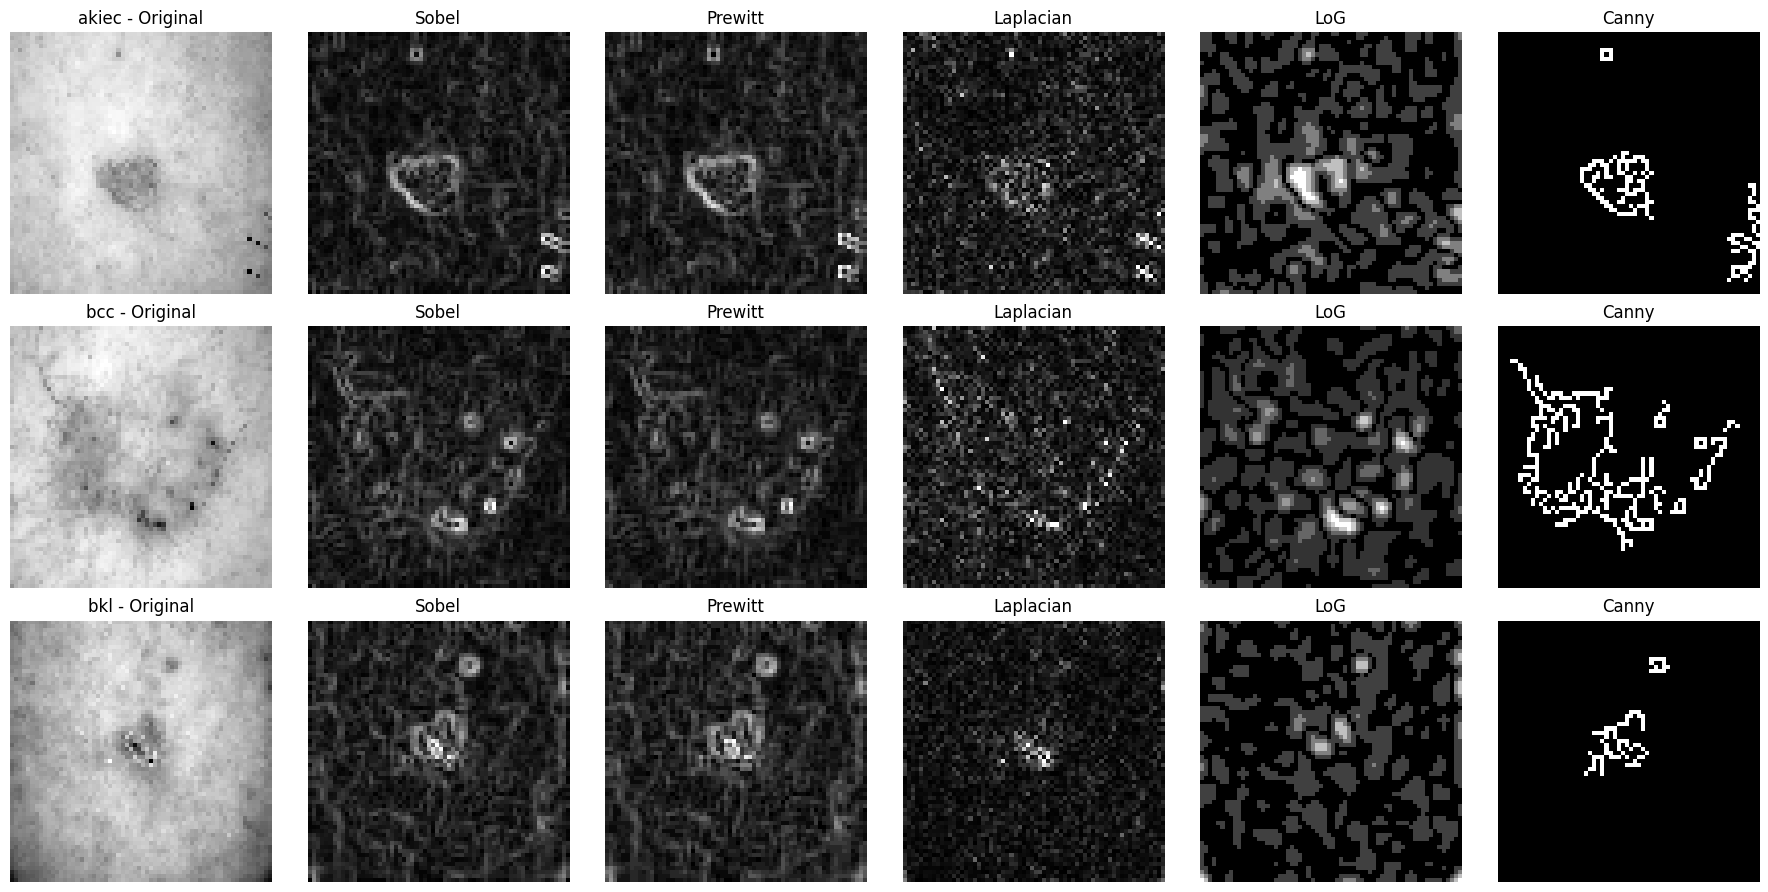

In [9]:

sample_classes = classes[:3] if len(classes) >= 3 else classes
sample_paths = [data[data["dx"] == c].iloc[0]["path"] for c in sample_classes]

methods = [
    ("Original", lambda g: g),
    ("Sobel", edge_sobel_mag),
    ("Prewitt", edge_prewitt),
    ("Laplacian", edge_laplacian),
    ("LoG", edge_log),
    ("Canny", edge_canny),
]

fig, axes = plt.subplots(len(sample_paths), len(methods), figsize=(3*len(methods), 3*len(sample_paths)))
for i, (path, cls) in enumerate(zip(sample_paths, sample_classes)):
    gray = load_gray(path)
    for j, (name, fn) in enumerate(methods):
        out = fn(gray)
        ax = axes[i, j] if len(sample_paths) > 1 else axes[j]
        ax.imshow(out, cmap="gray")
        ax.set_title(f"{cls} - {name}" if j == 0 else name)
        ax.axis("off")
plt.tight_layout()
plt.savefig("task1_edge_comparison.png", dpi=150)
plt.show()


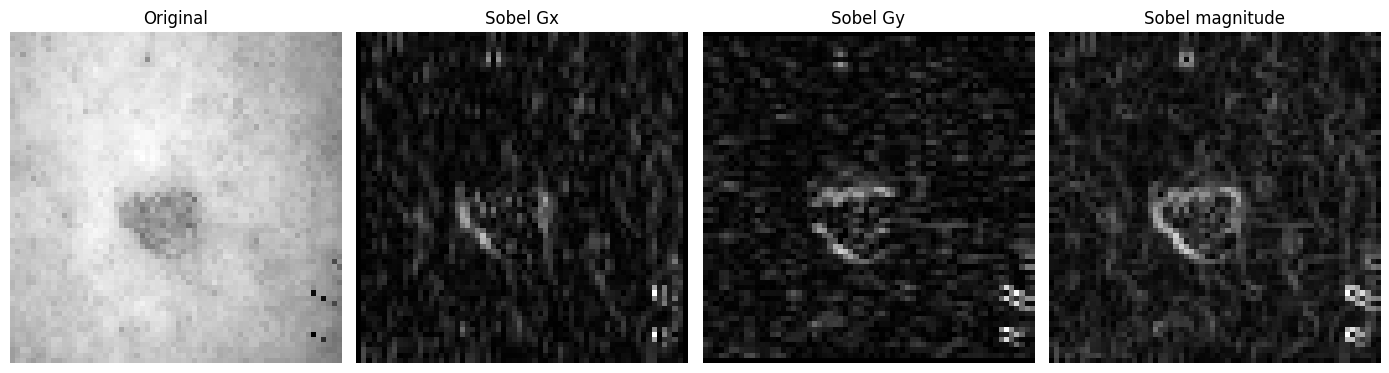

In [10]:

gray = load_gray(sample_paths[0])
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (name, fn) in zip(axes, [("Original", lambda g: g), ("Sobel Gx", edge_sobel_x),
                                  ("Sobel Gy", edge_sobel_y), ("Sobel magnitude", edge_sobel_mag)]):
    ax.imshow(fn(gray), cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()


## Task 2: Effect of Noise on Edge Detection


In [11]:
def add_gaussian_noise(gray, mean=0, sigma=25):
    noise = np.random.normal(mean, sigma, gray.shape)
    noisy = gray.astype(float) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)

def add_salt_pepper_noise(gray, amount=0.03):
    noisy = gray.copy()
    n_salt = int(amount * gray.size * 0.5)
    n_pepper = int(amount * gray.size * 0.5)
    coords = [np.random.randint(0, i, n_salt) for i in gray.shape]
    noisy[coords[0], coords[1]] = 255
    coords = [np.random.randint(0, i, n_pepper) for i in gray.shape]
    noisy[coords[0], coords[1]] = 0
    return noisy

def gaussian_filter(gray, k=5):
    return cv2.GaussianBlur(gray, (k, k), 0)

def median_filter(gray, k=5):
    return cv2.medianBlur(gray, k)


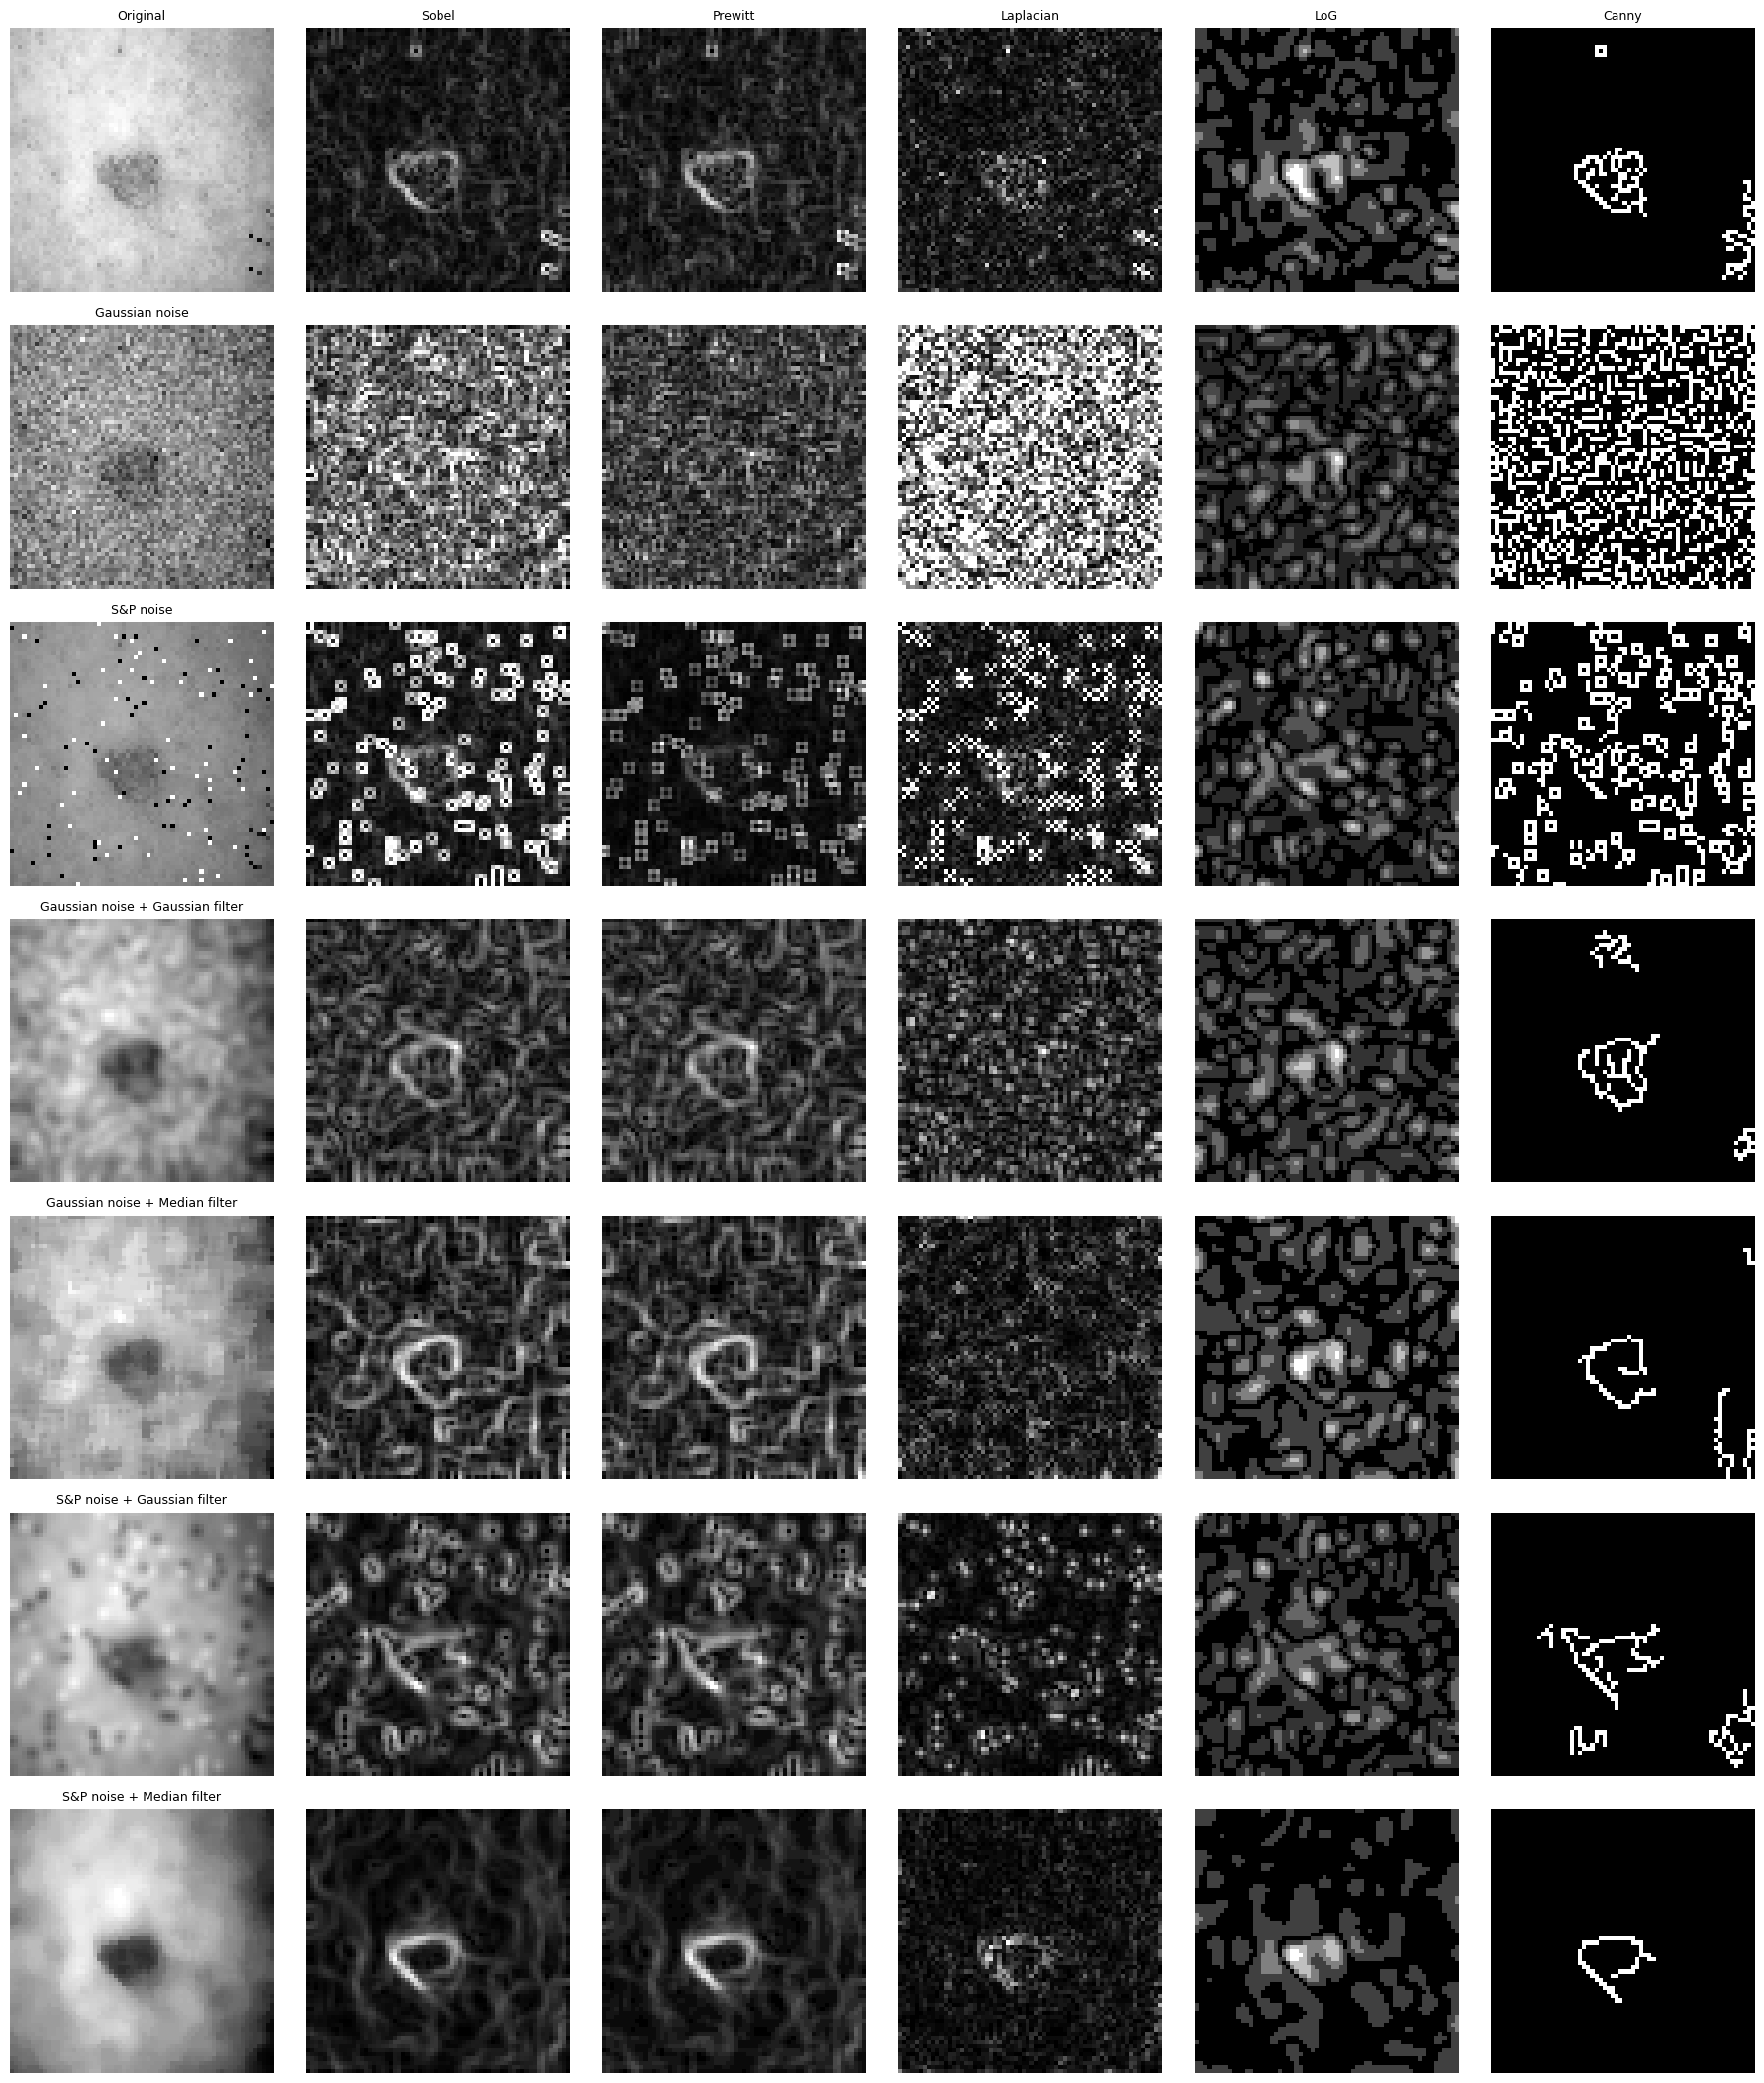

In [12]:
test_gray = load_gray(sample_paths[0])
variants = {
    "Original": test_gray,
    "Gaussian noise": add_gaussian_noise(test_gray),
    "S&P noise": add_salt_pepper_noise(test_gray),
}
variants["Gaussian noise + Gaussian filter"] = gaussian_filter(variants["Gaussian noise"])
variants["Gaussian noise + Median filter"] = median_filter(variants["Gaussian noise"])
variants["S&P noise + Gaussian filter"] = gaussian_filter(variants["S&P noise"])
variants["S&P noise + Median filter"] = median_filter(variants["S&P noise"])

edge_methods_task2 = [("Sobel", edge_sobel_mag), ("Prewitt", edge_prewitt),
                      ("Laplacian", edge_laplacian), ("LoG", edge_log), ("Canny", edge_canny)]

fig, axes = plt.subplots(len(variants), len(edge_methods_task2) + 1,
                          figsize=(3*(len(edge_methods_task2)+1), 3*len(variants)))
for i, (vname, vimg) in enumerate(variants.items()):
    axes[i, 0].imshow(vimg, cmap="gray"); axes[i, 0].set_title(vname, fontsize=9); axes[i, 0].axis("off")
    for j, (ename, efn) in enumerate(edge_methods_task2, start=1):
        axes[i, j].imshow(efn(vimg), cmap="gray")
        axes[i, j].set_title(ename if i == 0 else "", fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.savefig("task2_noise_comparison.png", dpi=150)
plt.show()


In [13]:

rows = []
for vname, vimg in variants.items():
    row = {"Image variant": vname}
    for ename, efn in edge_methods_task2:
        row[f"{ename} mean edge intensity"] = float(np.mean(efn(vimg)))
    rows.append(row)

table1 = pd.DataFrame(rows)
table1["Edge continuity (fill in)"] = ""
table1["Edge sharpness (fill in)"] = ""
table1["False/broken edges (fill in)"] = ""
table1


,Image variant,Sobel mean edge intensity,Prewitt mean edge intensity,Laplacian mean edge intensity,LoG mean edge intensity,Canny mean edge intensity,Edge continuity (fill in),Edge sharpness (fill in),False/broken edges (fill in)
0,Original,32.033447,5.568604,31.510498,0.597168,10.023193,,,
1,Gaussian noise,110.974365,19.088867,151.791504,1.162598,95.749512,,,
2,S&P noise,68.414307,12.342041,58.885742,0.989258,60.574951,,,
3,Gaussian noise + Gaussian filter,40.007324,6.978271,21.171387,0.872070,9.213867,,,
4,Gaussian noise + Median filter,31.106934,5.540527,26.728516,0.731934,7.221680,,,
5,S&P noise + Gaussian filter,33.471924,5.847412,16.032227,0.742920,10.770264,,,
6,S&P noise + Median filter,18.094971,3.230469,7.758301,0.380371,3.610840,,,


## Task 3: Parameter Analysis of Canny Edge Detection


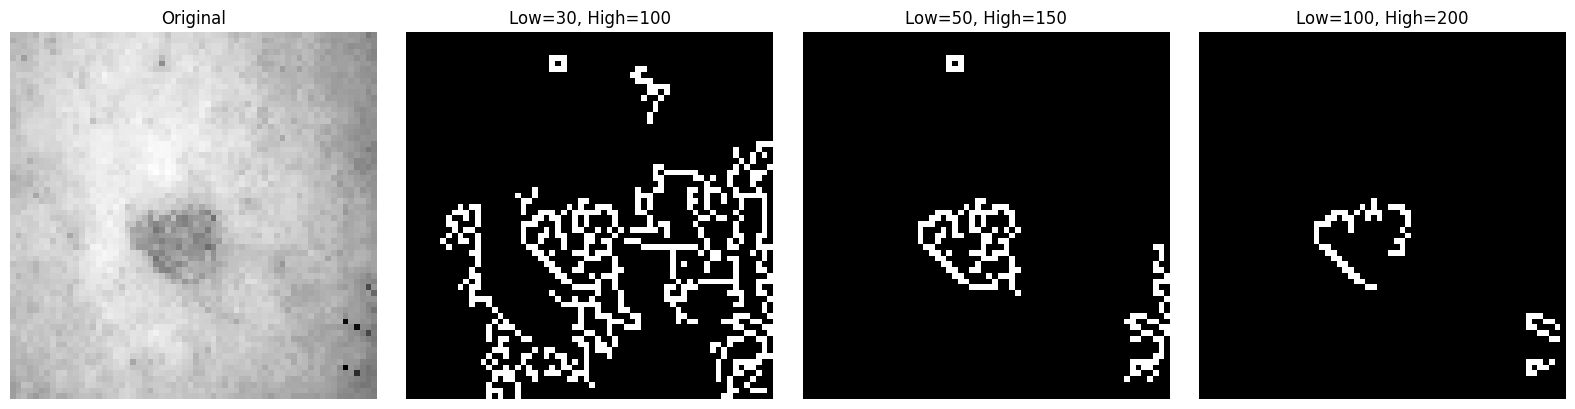

,Low threshold,High threshold,Edge pixel density,Observed quality (fill in)
0,30,100,0.137695,
1,50,150,0.039307,
2,100,200,0.018799,


In [14]:
canny_configs = [(30, 100), (50, 150), (100, 200)]

fig, axes = plt.subplots(1, len(canny_configs) + 1, figsize=(4*(len(canny_configs)+1), 4))
axes[0].imshow(test_gray, cmap="gray"); axes[0].set_title("Original"); axes[0].axis("off")
table2_rows = []
for ax, (low, high) in zip(axes[1:], canny_configs):
    out = cv2.Canny(test_gray, low, high)
    ax.imshow(out, cmap="gray"); ax.set_title(f"Low={low}, High={high}"); ax.axis("off")
    edge_density = float(np.mean(out > 0))
    table2_rows.append({"Low threshold": low, "High threshold": high,
                         "Edge pixel density": edge_density})
plt.tight_layout()
plt.savefig("task3_canny_thresholds.png", dpi=150)
plt.show()

table2 = pd.DataFrame(table2_rows)
table2["Observed quality (fill in)"] = ""
table2


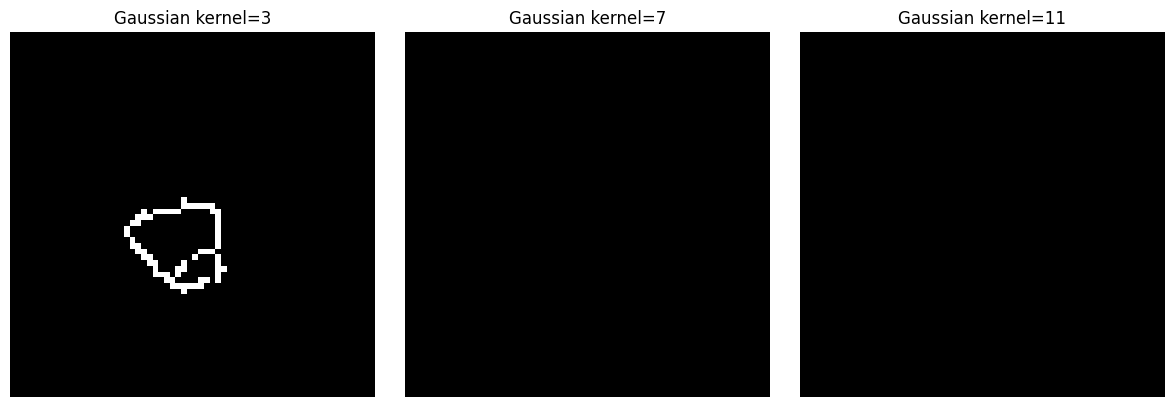

In [15]:

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, k in zip(axes, [3, 7, 11]):
    blurred = gaussian_filter(test_gray, k=k)
    out = cv2.Canny(blurred, 50, 150)
    ax.imshow(out, cmap="gray"); ax.set_title(f"Gaussian kernel={k}"); ax.axis("off")
plt.tight_layout()
plt.show
BEST_LOW, BEST_HIGH = 50, 150
BEST_EDGE_METHOD = "canny"   # used to build Set C in Task 4


## Task 4: Classification Using Edge Maps

In [16]:
label_encoder = {c: i for i, c in enumerate(classes)}
y_all = data["dx"].map(label_encoder).values

raw_images, filtered_images, edge_images = [], [], []
for path in data["path"]:
    gray = load_gray(path)
    raw_images.append(gray)
    filtered_images.append(gaussian_filter(gray, k=5))
    edge_images.append(edge_canny(gray, BEST_LOW, BEST_HIGH))

raw_images = np.array(raw_images)
filtered_images = np.array(filtered_images)
edge_images = np.array(edge_images)

print(raw_images.shape, filtered_images.shape, edge_images.shape)


(835, 64, 64) (835, 64, 64) (835, 64, 64)


In [17]:
def prep(x):
    x = x.astype("float32") / 255.0
    return x.reshape((-1, IMG_SIZE, IMG_SIZE, 1))

X_raw = prep(raw_images)
X_filtered = prep(filtered_images)
X_edge = prep(edge_images)
y = tf.keras.utils.to_categorical(y_all, num_classes=len(classes))

idx = np.arange(len(y))
idx_train, idx_temp = train_test_split(idx, test_size=0.3, random_state=SEED, stratify=y_all)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.5, random_state=SEED, stratify=y_all[idx_temp])

def split(X):
    return X[idx_train], X[idx_val], X[idx_test]

splits = {
    "Raw": (*split(X_raw), y[idx_train], y[idx_val], y[idx_test]),
    "Filtered": (*split(X_filtered), y[idx_train], y[idx_val], y[idx_test]),
    "Edge": (*split(X_edge), y[idx_train], y[idx_val], y[idx_test]),
}
print("Train/Val/Test sizes:", len(idx_train), len(idx_val), len(idx_test))


Train/Val/Test sizes: 584 125 126


In [18]:
def build_model(num_classes):
    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model


In [19]:
results = {}
trained_models = {}

for set_name, (Xtr, Xval, Xte, ytr, yval, yte) in splits.items():
    print(f"\n--- Training on: {set_name} ---")
    model = build_model(len(classes))

    t0 = time.time()
    model.fit(Xtr, ytr, validation_data=(Xval, yval),
              epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1)
    train_time = time.time() - t0

    t0 = time.time()
    y_pred_probs = model.predict(Xte, verbose=0)
    infer_time = time.time() - t0

    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = np.argmax(yte, axis=1)

    results[set_name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Training time (s)": train_time,
        "Inference time (s)": infer_time,
        "y_true": y_true,
        "y_pred": y_pred,
    }
    trained_models[set_name] = model



--- Training on: Raw ---
Epoch 1/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 192ms/step - accuracy: 0.1199 - loss: 1.9717 - val_accuracy: 0.1440 - val_loss: 1.9448
Epoch 2/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1592 - loss: 1.9435 - val_accuracy: 0.1440 - val_loss: 1.9386
Epoch 3/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2003 - loss: 1.8877 - val_accuracy: 0.2080 - val_loss: 1.8892
Epoch 4/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2586 - loss: 1.7790 - val_accuracy: 0.3120 - val_loss: 1.9055
Epoch 5/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3151 - loss: 1.7137 - val_accuracy: 0.2480 - val_loss: 1.9541
Epoch 6/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3082 - loss: 1.6663 - val_accuracy: 0.2800 - val_loss: 1.9154
Epoch 7/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3288 - loss: 1.6211 - val_accuracy: 0.2480 - val_loss: 1.8971
Epoch 8/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3818 - loss: 1.5412 - v

## Task 5: Classification Performance Comparison

In [20]:
table3 = pd.DataFrame({
    name: {k: v for k, v in res.items() if k not in ("y_true", "y_pred")}
    for name, res in results.items()
}).T
table3


,Accuracy,Precision,Recall,F1-score,Training time (s),Inference time (s)
Raw,0.325397,0.333639,0.325397,0.310382,11.151141,0.914761
Filtered,0.317460,0.334734,0.317460,0.306179,8.898100,0.628144
Edge,0.158730,0.166330,0.158730,0.155801,9.003372,0.595546


## Task 6: Visual Comparison of Classification Results
Confusion matrices for Raw, Filtered, and Edge images, plus a bar chart comparing metrics.

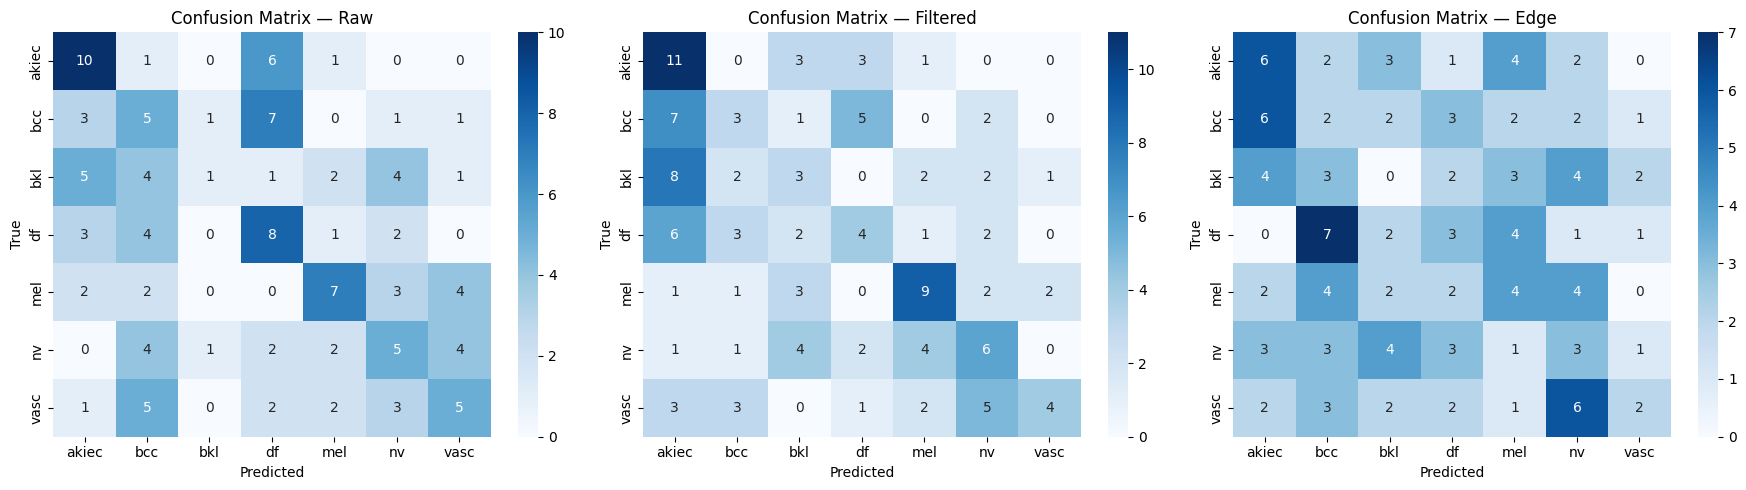

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(res["y_true"], res["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=classes, yticklabels=classes)
    ax.set_title(f"Confusion Matrix — {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.savefig("task6_confusion_matrices.png", dpi=150)
plt.show()


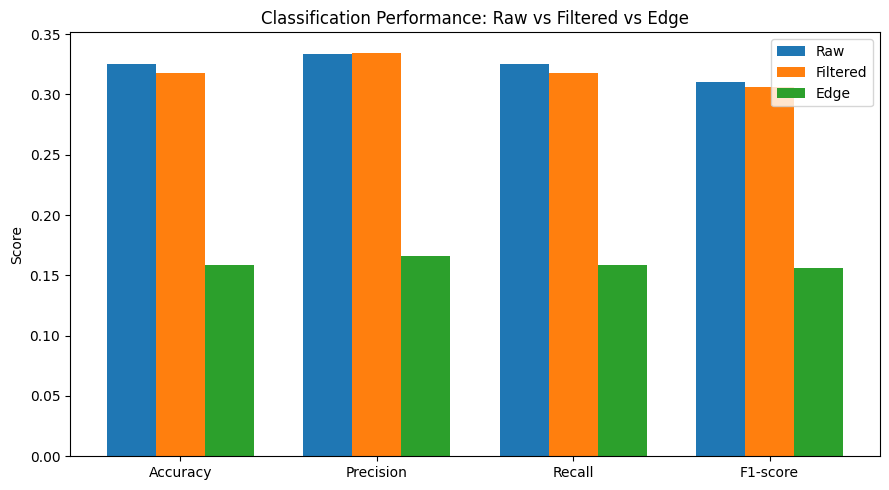

In [22]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-score"]
x = np.arange(len(metrics_to_plot))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))
for i, (name, res) in enumerate(results.items()):
    values = [res[m] for m in metrics_to_plot]
    ax.bar(x + i*width, values, width, label=name)

ax.set_xticks(x + width)
ax.set_xticklabels(metrics_to_plot)
ax.set_ylabel("Score")
ax.set_title("Classification Performance: Raw vs Filtered vs Edge")
ax.legend()
plt.tight_layout()
plt.savefig("task6_metric_comparison.png", dpi=150)
plt.show()
